# Backup Airlines — Minería de datos: detección de sesiones de riesgo
**Curso:** Minería de Datos I · **Docente:** Ing. Cristian Camilo Cuadrado Beltrán  
**Integrantes:** Gabriel Santiago Osorio Piñeres · Jhon Jairo Carmona Macea

Este notebook recorre las seis etapas propuestas por MinedApp (problema, datos, preprocesamiento, modelado, evaluación y reporte) sobre la bitácora de actividad de Backup Airlines. Todos los números que aparecen aquí se producen al ejecutar las celdas; ninguno se escribió a mano.

> **Sobre los datos:** la bitácora de la aplicación vive en una base H2 en memoria y todavía no hay uso real por parte de empresas. Por eso se trabaja con un dataset **simulado** que respeta el esquema de la tabla `activity_logs` y las acciones que registra la aplicación (ver `data/README.md`). Los resultados validan el procedimiento, no el desempeño en producción.

## Etapa 1. Problema

**Pregunta:** ¿es posible identificar automáticamente, a partir de la bitácora de actividad, las sesiones de uso cuyo comportamiento se aparta del habitual (descargas, borrados o comparticiones masivas, o actividad fuera de horario) para priorizar su revisión en una auditoría?

**Tipo de tarea:** *Otro → detección de anomalías* (no supervisada). No existe una variable objetivo real: la empresa no tiene incidentes etiquetados. Por eso se descarta la clasificación supervisada y no se inventan etiquetas para entrenar.

**Unidad de análisis:** la sesión de un usuario (eventos separados por menos de 30 minutos, igual que el timeout de sesión configurado en la aplicación).

In [1]:
import os, sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))
import generar_dataset, preparacion, modelo
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
RES = 'resultados'; os.makedirs(RES, exist_ok=True)

# Regenera el dataset y las sesiones desde cero (semilla fija = resultados reproducibles)
generar_dataset.generar()
preparacion.main()

Eventos: 27,998 | sesiones generadas: 2,962 | inyectadas: 100


Eventos: 27,998 -> sesiones: 2,948 | variables: 17


## Etapa 2. Datos
### 2.1 Bitácora de eventos (formato de la tabla `activity_logs`)

In [2]:
logs = pd.read_csv('../data/raw/activity_logs_simulados.csv')
print(logs.shape)
logs.head(10)

(27998, 6)


,id,created_at,username,rol,action,file_id
0,1,2026-07-01 03:14:00,calid07,calidad_cumplimiento,SHARE_FILE,464
1,2,2026-07-01 03:16:35,calid07,calidad_cumplimiento,DOWNLOAD_FILE,442
2,3,2026-07-01 03:18:04,calid07,calidad_cumplimiento,DOWNLOAD_FILE,86
3,4,2026-07-01 03:19:34,calid07,calidad_cumplimiento,UPLOAD_FILE,129
4,5,2026-07-01 03:21:37,calid07,calidad_cumplimiento,DOWNLOAD_FILE,133
5,6,2026-07-01 03:24:02,calid07,calidad_cumplimiento,DOWNLOAD_FILE,365
6,7,2026-07-01 03:26:33,calid07,calidad_cumplimiento,DOWNLOAD_FILE,226
7,8,2026-07-01 03:27:57,calid07,calidad_cumplimiento,SHARE_FILE,80
8,9,2026-07-01 03:28:45,calid07,calidad_cumplimiento,DOWNLOAD_FILE,597
9,10,2026-07-01 03:32:45,calid07,calidad_cumplimiento,UPLOAD_FILE,164


In [3]:
print(logs['action'].value_counts())
print('\nUsuarios:', logs['username'].nunique(), '| Periodo:', logs['created_at'].min(), '→', logs['created_at'].max())

action
PREVIEW_FILE       8425
DOWNLOAD_FILE      7682
UPLOAD_FILE        7107
SHARE_FILE         2004
DELETE_FILE        1899
RESTORE_VERSION     881
Name: count, dtype: int64

Usuarios: 35 | Periodo: 2026-07-01 03:14:00 → 2026-09-29 19:07:19


### 2.2 Dataset de sesiones (archivo que se carga en MinedApp)

In [4]:
s = pd.read_csv('../data/processed/sesiones_backup_airlines.csv')
print('Registros:', s.shape[0], '| Columnas:', s.shape[1])
s.head(10)

Registros: 2948 | Columnas: 22


,session_id,username,rol,fecha,inicio,n_eventos,duracion_min,eventos_por_min,archivos_distintos,n_upload,n_download,n_preview,n_share,n_delete,n_restore_version,pct_download,pct_delete,pct_share,hora_inicio,fuera_horario,fin_de_semana,pct_archivos_nuevos
0,1921,calid07,calidad_cumplimiento,2026-07-01,2026-07-01 03:14:00,12,23.78,0.484,12,2,8,0,2,0,0,0.667,0.000,0.167,3,1,0,NaN
1,2284,coord03,coordinador_documentacion,2026-07-01,2026-07-01 07:20:00,8,23.72,0.324,8,4,2,1,0,1,0,0.250,0.125,0.000,7,0,0,NaN
2,1326,auxil15,auxiliar_operaciones,2026-07-01,2026-07-01 07:40:00,10,61.78,0.159,9,4,0,5,0,1,0,0.000,0.100,0.000,7,0,0,NaN
3,1247,auxil14,auxiliar_operaciones,2026-07-01,2026-07-01 08:02:00,10,43.87,0.223,10,4,0,4,1,1,0,0.000,0.100,0.100,8,0,0,NaN
4,2842,coord08,coordinador_documentacion,2026-07-01,2026-07-01 08:16:00,13,66.93,0.191,10,3,3,3,1,3,0,0.231,0.231,0.077,8,0,0,NaN
5,1505,calid01,calidad_cumplimiento,2026-07-01,2026-07-01 08:23:00,9,38.10,0.230,7,1,3,5,0,0,0,0.333,0.000,0.000,8,0,0,NaN
6,1922,calid07,calidad_cumplimiento,2026-07-01,2026-07-01 08:26:00,11,64.45,0.168,9,0,4,5,2,0,0,0.364,0.000,0.182,8,0,0,1.0
7,1,admin01,administrador,2026-07-01,2026-07-01 08:40:00,4,18.25,0.208,4,0,1,2,1,0,0,0.250,0.000,0.250,8,0,0,NaN
8,1059,auxil12,auxiliar_operaciones,2026-07-01,2026-07-01 09:02:00,4,16.03,0.235,4,3,1,0,0,0,0,0.250,0.000,0.000,9,0,0,NaN
9,1837,calid06,calidad_cumplimiento,2026-07-01,2026-07-01 09:11:00,3,12.62,0.220,3,1,0,1,1,0,0,0.000,0.000,0.333,9,0,0,NaN


In [5]:
s[preparacion.FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
n_eventos,2948.0,9.50,8.82,2.00,5.00,8.00,11.00,115.00
duracion_min,2948.0,38.22,23.10,1.83,20.45,34.68,51.39,196.60
eventos_por_min,2948.0,0.29,0.37,0.13,0.19,0.22,0.26,3.26
archivos_distintos,2948.0,8.83,8.12,2.00,5.00,8.00,10.00,107.00
n_upload,2948.0,2.41,1.95,0.00,1.00,2.00,4.00,10.00
n_download,2948.0,2.61,7.37,0.00,1.00,1.00,3.00,108.00
n_preview,2948.0,2.86,2.04,0.00,1.00,3.00,4.00,16.00
n_share,2948.0,0.68,2.01,0.00,0.00,0.00,1.00,33.00
n_delete,2948.0,0.64,2.68,0.00,0.00,0.00,1.00,44.00
n_restore_version,2948.0,0.30,0.59,0.00,0.00,0.00,0.00,4.00


### 2.3 Valores nulos por columna

In [6]:
nulos = s.isna().sum(); nulos[nulos > 0]

pct_archivos_nuevos    35
dtype: int64

La única columna con nulos es `pct_archivos_nuevos`: es nula en la **primera sesión de cada usuario**, porque no hay historial previo contra el cual comparar. Es un nulo estructural, no un error de captura.

### 2.4 Valores atípicos (método IQR, Q1 − 1.5·IQR, Q3 + 1.5·IQR)

In [7]:
filas = []
for c in preparacion.FEATURES:
    q1, q3 = s[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((s[c] < q1 - 1.5*iqr) | (s[c] > q3 + 1.5*iqr)).sum()
    filas.append((c, round(q1,3), round(q3,3), int(n), round(100*n/len(s),2)))
atip = pd.DataFrame(filas, columns=['variable','Q1','Q3','atipicos','%']).sort_values('atipicos', ascending=False)
atip

,variable,Q1,Q3,atipicos,%
9,n_restore_version,0.000,0.000,701,23.78
16,pct_archivos_nuevos,0.000,0.091,523,17.74
2,eventos_por_min,0.190,0.263,220,7.46
11,pct_delete,0.000,0.091,206,6.99
7,n_share,0.000,1.000,130,4.41
5,n_download,1.000,3.000,129,4.38
12,pct_share,0.000,0.100,118,4.00
3,archivos_distintos,5.000,10.000,106,3.60
0,n_eventos,5.000,11.000,95,3.22
8,n_delete,0.000,1.000,68,2.31


Los atípicos **no se eliminan**: en este problema un valor extremo (por ejemplo, 100 descargas en una sesión) es precisamente lo que se quiere detectar. Variables binarias como `fuera_horario` aparecen con muchos 'atípicos' porque casi siempre valen 0; el método IQR no es informativo para ellas.

### 2.5 Histogramas

In [8]:
vars_hist = ['n_eventos','duracion_min','eventos_por_min','archivos_distintos','n_download','n_delete','n_share','hora_inicio','pct_archivos_nuevos']
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, c in zip(axes.ravel(), vars_hist):
    ax.hist(s[c].dropna(), bins=40, color='#003580', alpha=.85); ax.set_title(c, fontsize=10)
fig.suptitle('Distribución de variables por sesión', fontsize=12); fig.tight_layout()
fig.savefig(f'{RES}/histogramas.png', dpi=150); plt.show()

### 2.6 Matriz de correlación

In [9]:
corr = s[preparacion.FEATURES].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8); ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iat[i,j]:.1f}', ha='center', va='center', fontsize=6)
fig.colorbar(im, fraction=.046); ax.set_title('Matriz de correlación (Pearson)'); fig.tight_layout()
fig.savefig(f'{RES}/matriz_correlacion.png', dpi=150); plt.show()
pares = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(key=abs, ascending=False)
pares.head(8).round(3)

n_eventos           archivos_distintos    0.994
                    n_download            0.876
archivos_distintos  n_download            0.873
n_share             pct_share             0.763
n_delete            pct_delete            0.730
eventos_por_min     archivos_distintos    0.675
n_eventos           eventos_por_min       0.650
duracion_min        n_preview             0.608
dtype: float64

### 2.7 Patrón horario de la actividad

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.5))
s['hora_inicio'].value_counts().sort_index().plot.bar(ax=ax, color='#003580')
ax.set_xlabel('Hora de inicio de la sesión'); ax.set_ylabel('Sesiones'); ax.set_title('Sesiones por hora de inicio')
fig.tight_layout(); fig.savefig(f'{RES}/sesiones_por_hora.png', dpi=150); plt.show()
s.groupby('rol')[['n_eventos','n_download','n_delete','n_share']].mean().round(2)

,n_eventos,n_download,n_delete,n_share
rol,,,,
administrador,6.69,1.82,1.54,0.28
auxiliar_operaciones,7.88,1.66,0.58,0.46
calidad_cumplimiento,11.27,5.15,0.40,0.52
coordinador_documentacion,11.31,2.57,0.76,1.19


## Etapa 3. Preprocesamiento

Decisiones tomadas (y por qué):

| Decisión | Aplicada | Justificación |
|---|---|---|
| Sesionización (gap > 30 min) | Sí | Convierte eventos sueltos en una unidad comparable; 30 min = timeout de sesión de la app. |
| Imputación de nulos | Sí, mediana | Solo `pct_archivos_nuevos`, nulo estructural en la 1.ª sesión de cada usuario. Mediana por ser robusta a la asimetría. |
| Tratamiento de atípicos | **No** | Los extremos son la señal que se busca; eliminarlos destruiría el objetivo del análisis. |
| Escalado | Sí, StandardScaler | Las variables tienen escalas muy distintas (proporciones 0–1 frente a conteos de >100). |
| Codificación categórica | No | `username` y `rol` no entran al modelo (se evita que aprenda identidades); todas las predictoras son numéricas. |

Imputación y escalado se ajustan **solo con el conjunto de entrenamiento** dentro de un `Pipeline` de scikit-learn y luego se aplican al de prueba.

In [11]:
train, test = modelo.dividir(s)
print('Entrenamiento (jul–ago):', len(train), 'sesiones | Prueba (sep):', len(test), 'sesiones')
modelo.construir_pipeline()

Entrenamiento (jul–ago): 1997 sesiones | Prueba (sep): 951 sesiones


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputar', ...), ('escalar', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. 

## Etapa 4. Modelado

- **Algoritmo:** Isolation Forest (300 árboles, `contamination=0.03`, `random_state=42`). Aísla observaciones con particiones aleatorias: las sesiones raras quedan aisladas con pocos cortes. No necesita etiquetas y escala bien a muchos registros.
- **Referencia sencilla:** regla de umbrales: marcar la sesión si alguna variable de conteo supera Q3 + 3·IQR del entrenamiento o si inicia fuera de horario.
- **División:** temporal. Se entrena con julio–agosto y se prueba con septiembre, como ocurriría en la práctica (el modelo nunca ve el futuro).

In [12]:
out = modelo.ejecutar(guardar=True)
pd.DataFrame(out['resultados']).set_index('modelo')

,precision,recall,f1,sesiones_marcadas,TP,FP,FN,TN,average_precision,precision_at_k
modelo,,,,,,,,,,
Isolation Forest,0.905,0.679,0.776,21,19,2,9,921,0.949,0.857
Regla IQR + horario (referencia),0.483,1.000,0.651,58,28,30,0,893,NaN,NaN
Híbrido IF + fuera de horario (posterior),0.812,0.929,0.867,32,26,6,2,917,NaN,NaN


## Etapa 5. Evaluación

Para medir el desempeño se usan los **escenarios inyectados** en la simulación (archivo `etiquetas_validacion.csv`), que nunca participaron del entrenamiento.

- **Precisión:** de las sesiones que el modelo marca, cuántas eran realmente de riesgo. Importa porque cada alerta consume tiempo del auditor.
- **Recall:** de las sesiones de riesgo, cuántas encontró. Importa porque un borrado masivo no detectado es pérdida de evidencia.
- **F1:** equilibrio entre ambas.
- **Average precision (área bajo la curva PR):** evalúa el puntaje de riesgo como *ranking*, útil cuando el auditor revisa primero las sesiones con mayor puntaje.
- **Precision@k:** precisión de las k sesiones con mayor puntaje, con k = número de sesiones de riesgo en prueba.

In [13]:
print(json.dumps(out['dataset'], ensure_ascii=False, indent=1)[:400])
pd.DataFrame(out['por_escenario'])

{
 "sesiones_total": 2948,
 "entrenamiento": 1997,
 "prueba": 951,
 "anomalas_en_prueba": 28,
 "tasa_anomalas_prueba": 0.0294,
 "variables": [
  "n_eventos",
  "duracion_min",
  "eventos_por_min",
  "archivos_distintos",
  "n_upload",
  "n_download",
  "n_preview",
  "n_share",
  "n_delete",
  "n_restore_version",
  "pct_download",
  "pct_delete",
  "pct_share",
  "hora_inicio",
  "fuera_horario",


,escenario,sesiones,detectadas_iforest,detectadas_regla,detectadas_hibrido
0,borrado_masivo,4,4,4,4
1,comparticion_masiva,8,6,8,6
2,descarga_masiva,7,7,7,7
3,fuera_de_horario,9,2,9,9


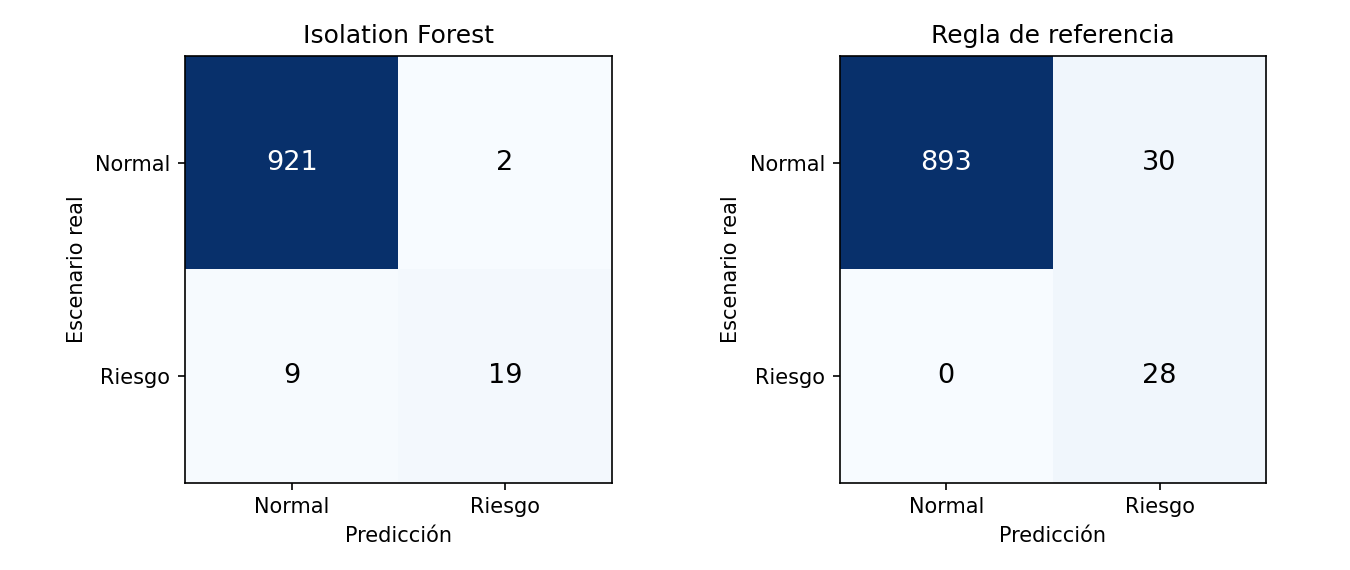

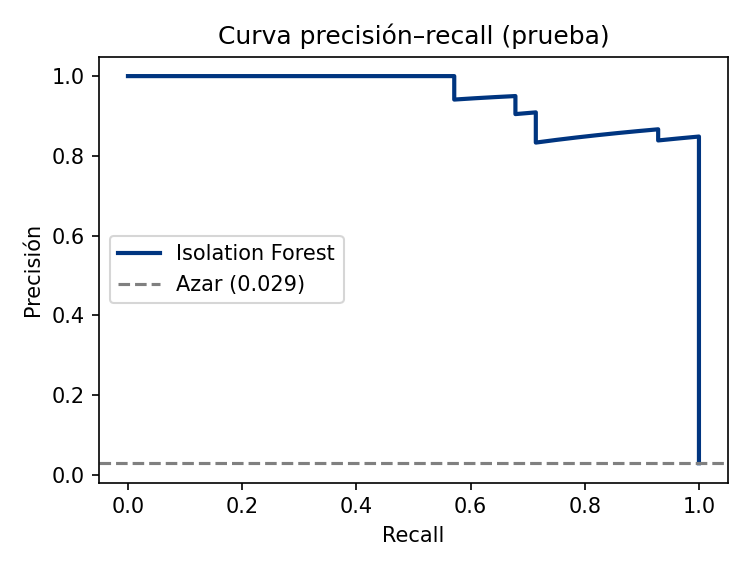

In [14]:
from IPython.display import Image, display
display(Image(f'{RES}/matriz_confusion.png')); display(Image(f'{RES}/curva_pr.png'))

### Sesiones con mayor puntaje de riesgo en septiembre

In [15]:
t = out['_test']
t.nlargest(10, 'puntaje_riesgo')[['session_id','username','inicio','n_eventos','n_download','n_delete','n_share','fuera_horario','pct_archivos_nuevos','puntaje_riesgo','escenario']].round(3)

,session_id,username,inicio,n_eventos,n_download,n_delete,n_share,fuera_horario,pct_archivos_nuevos,puntaje_riesgo,escenario
2719,1151,auxil12,2026-09-22 10:07:00,105,93,0,5,0,0.699,0.715,descarga_masiva
2186,1488,auxil16,2026-09-05 15:49:00,110,100,0,3,0,0.720,0.715,descarga_masiva
2258,1976,calid07,2026-09-08 11:25:00,115,108,0,2,0,0.645,0.710,descarga_masiva
2435,2373,coord03,2026-09-13 10:40:00,79,73,0,2,0,0.486,0.708,descarga_masiva
2827,218,auxil01,2026-09-25 07:08:00,95,83,0,6,0,0.769,0.707,descarga_masiva
2658,1915,calid06,2026-09-19 08:32:00,87,79,0,3,0,0.571,0.691,descarga_masiva
2637,2157,coord01,2026-09-18 13:23:00,37,3,0,33,0,0.946,0.680,comparticion_masiva
2663,1749,calid04,2026-09-21 08:40:00,56,7,38,1,0,0.642,0.670,borrado_masivo
2507,780,auxil08,2026-09-15 11:18:00,75,66,2,0,0,0.779,0.668,descarga_masiva
2098,2579,coord05,2026-09-03 09:19:00,35,3,31,0,0,0.882,0.658,borrado_masivo


### Errores del modelo: sesiones de riesgo no detectadas y falsas alarmas

In [16]:
print('No detectadas (FN):'); display(t[(t.es_anomala==1)&(t.pred_iforest==0)][['session_id','inicio','n_eventos','n_download','n_share','hora_inicio','fuera_horario','puntaje_riesgo','escenario']].round(3))
print('Falsas alarmas (FP):'); display(t[(t.es_anomala==0)&(t.pred_iforest==1)][['session_id','rol','inicio','n_eventos','n_download','hora_inicio','puntaje_riesgo']].round(3))

No detectadas (FN):


,session_id,inicio,n_eventos,n_download,n_share,hora_inicio,fuera_horario,puntaje_riesgo,escenario
1998,850,2026-09-01 02:20:00,12,6,2,2,1,0.555,fuera_de_horario
2048,1035,2026-09-02 02:00:00,11,5,1,2,1,0.539,fuera_de_horario
2183,2807,2026-09-05 02:55:00,22,14,1,2,1,0.603,fuera_de_horario
2286,1816,2026-09-09 07:25:00,14,2,10,7,0,0.608,comparticion_masiva
2336,860,2026-09-10 01:58:00,19,10,3,1,1,0.601,fuera_de_horario
2337,370,2026-09-10 03:07:00,19,10,3,3,1,0.599,fuera_de_horario
2686,960,2026-09-21 13:37:00,30,4,20,13,0,0.601,comparticion_masiva
2744,1053,2026-09-22 23:33:00,23,16,1,23,1,0.614,fuera_de_horario
2868,885,2026-09-26 02:12:00,20,9,4,2,1,0.603,fuera_de_horario


Falsas alarmas (FP):


,session_id,rol,inicio,n_eventos,n_download,hora_inicio,puntaje_riesgo
2833,1990,calidad_cumplimiento,2026-09-25 08:34:00,34,20,8,0.623
2846,1636,calidad_cumplimiento,2026-09-25 11:16:00,33,16,11,0.616


## Etapa 6. Reporte

In [17]:
r = {x['modelo']: x for x in out['resultados']}
iff, rg, hb = r['Isolation Forest'], r['Regla IQR + horario (referencia)'], r['Híbrido IF + fuera de horario (posterior)']
print(f"Isolation Forest -> precisión {iff['precision']}, recall {iff['recall']}, F1 {iff['f1']}, AP {iff['average_precision']}")
print(f"Regla referencia -> precisión {rg['precision']}, recall {rg['recall']}, F1 {rg['f1']}")
print(f"Híbrido (posterior) -> precisión {hb['precision']}, recall {hb['recall']}, F1 {hb['f1']}")

Isolation Forest -> precisión 0.905, recall 0.679, F1 0.776, AP 0.949
Regla referencia -> precisión 0.483, recall 1.0, F1 0.651
Híbrido (posterior) -> precisión 0.812, recall 0.929, F1 0.867


**Conclusiones del procedimiento** (sobre datos simulados):

1. El Isolation Forest identifica con alta precisión los comportamientos *volumétricos* (descargas, borrados y comparticiones masivas) y genera muy pocas falsas alarmas frente a la regla de umbrales.
2. Su punto débil es la actividad **fuera de horario con pocos eventos**: una sola variable binaria pesa poco entre 17 dimensiones. La regla sí la captura, pero a costa de muchas falsas alarmas.
3. Como análisis posterior —no planeado de antemano— combinar el modelo con la marca de horario mejora el F1. Esa combinación debe validarse con datos nuevos antes de adoptarse.
4. Los resultados **no** son una medida de desempeño en producción: provienen de escenarios simulados. El siguiente paso es recolectar la bitácora real mediante `/admin/logs/export.csv`.